# 19 · 曝光、标签、缺失与无泄漏切分

第18章保留总览；本章单独深入一个问题。正式200k实验不覆盖，教学训练使用独立共享记录。

## 先预测：这一行究竟是什么？

Criteo每行是一次已发生的曝光，label=1/0表示点击/未点击，不是推荐系统的未观察交互。13个整数特征、26个匿名类别；字段含义没有公开，不能把字段擅自叫作年龄、广告主或用户。类别值是匿名哈希，不是可解释的连续数。

本章只读取同一个固定SHA分片的前40,000行。张量X为[N,39]，y为[N]。先猜正例比例及哪个数值列缺失最多，再执行。这里的点击率属于被抽样的日志，不等于流量总体CTR。

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd()
if not (ROOT/'reclab').is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from reclab.ads import latest, load_data, split_groups, NUM, CAT, FEATURES
from reclab.paths import ARTIFACTS
from reclab.probability import evaluate
preview=ARTIFACTS/'notebook-previews';preview.mkdir(parents=True,exist_ok=True)
frame,total=load_data(40000)
y=frame.label.to_numpy()
print('X shape:',frame[FEATURES].shape,'y shape:',y.shape,'shard rows:',total)
print('Actual clicked:',int(y.sum()),'sample CTR:',float(y.mean()))
display(pd.DataFrame({'missing_rate':frame[NUM].isna().mean(),'dtype':frame[NUM].dtypes.astype(str)}))

X shape: (40000, 39) y shape: (40000,) shard rows: 766864
Actual clicked: 1200 sample CTR: 0.03


,missing_rate,dtype
integer_feature_1,0.187575,float64
integer_feature_2,0.093375,float64
integer_feature_3,0.249075,float64
integer_feature_4,0.445175,float64
integer_feature_5,0.411575,float64
integer_feature_6,0.104150,float64
integer_feature_7,0.032600,float64
integer_feature_8,0.000000,float64
integer_feature_9,0.000000,float64
integer_feature_10,0.104150,float64


## 缺失是输入状态，不是零点击

数值缺失和数值0是不同的信息。中位数必须只在train上估计，缺失指示还能让线性模型知道值被填补。树可以学习缺失路由。类别空值使用明确标记，训练未见类别另走other桶。

先预测：如果缺失多的样本点击率较低，能否说“缺失导致不点击”？不能：曝光来源、用户和业务上下文都未披露。下面按缺失数量分段仅用于误差诊断。

,count,mean
missing,,
0,11173,0.034458
1,6562,0.028345
2,4131,0.030743
3,9145,0.024057
4,3130,0.030990
5,2364,0.032149
6,1304,0.039110
7,840,0.023810
8,732,0.023224


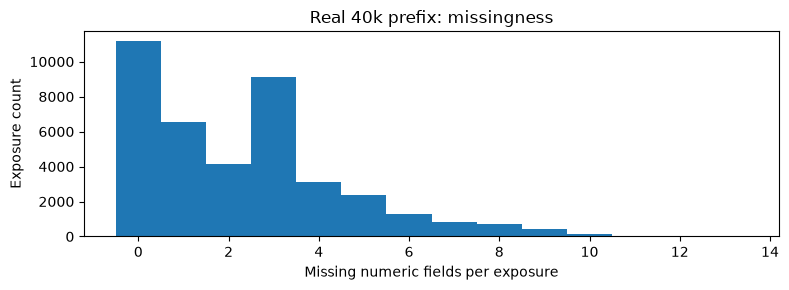

In [2]:
missing=frame[NUM].isna().sum(axis=1)
display(pd.DataFrame({'missing':missing,'label':y}).groupby('missing').label.agg(['count','mean']))
fig,ax=plt.subplots(figsize=(8,3));ax.hist(missing,bins=np.arange(15)-.5)
ax.set(xlabel='Missing numeric fields per exposure',ylabel='Exposure count',title='Real 40k prefix: missingness')
fig.tight_layout();fig.savefig(preview/'19_data.png',dpi=130);plt.show()

## 只改一个变量：标签变化不应改变分区

行号随机切分可能把完全相同特征的曝光分到训练与评估。当前实现对39个特征哈希分组，不包含label；同一个组总在同一分区。它只能避免完全重复向量的泄漏，不能消除同用户、同会话或时间相关性。无公开用户ID和可靠分片时间戳，所以不能声称用户或时间隔离。

执行原始分区，再只翻转label。分区必须完全相同。训练、select、calibration和audit各自做什么，应能在看结果前说清楚。

In [3]:
masks,groups=split_groups(frame)
flipped=frame.copy();flipped['label']=1-flipped.label
changed,newgroups=split_groups(flipped)
assert np.array_equal(groups,newgroups)
for a,ma in masks.items():
    for b,mb in masks.items():
        if a!=b: assert not set(groups[ma])&set(groups[mb])
display(pd.DataFrame({name:{'rows':int(mask.sum()),'clicks':int(y[mask].sum())} for name,mask in masks.items()}).T)
print('Label flip leaves all feature-group partitions unchanged.')

,rows,clicks
train,22024,677
select,6006,194
calibration,6008,161
audit,5962,168


Label flip leaves all feature-group partitions unchanged.


## 重复拷贝压力测试：明确的机制输入

原始前缀的重复可能极少。为了测试规则，下面**人为复制**100行特征，不能把这些拷贝计入真实曝光统计。只改变“切分单位”：随机行 versus 相同特征组。随机行会把复制品分散，组切分保持一致。这是程序不变量检查，不是新数据实验成绩。

In [4]:
toy=pd.concat([frame.iloc[:500],frame.iloc[:100]],ignore_index=True)
gm,gh=split_groups(toy)
rng=np.random.default_rng(42);random_train=rng.random(len(toy))<.55
random_overlap=set(gh[random_train])&set(gh[~random_train])
print('Constructed duplicate stress test, random-row group overlap:',len(random_overlap))
assert not set(gh[gm['train']])&set(gh[~gm['train']])
print('Grouped overlap: 0; synthetic copies are excluded from all reported real metrics.')

Constructed duplicate stress test, random-row group overlap: 43
Grouped overlap: 0; synthetic copies are excluded from all reported real metrics.


## 词表也要遵守训练边界

类别映射必须只从train学习；如果扫描评估数据再决定top类别，已经改变了学习协议。原模型使用每字段最多255个训练高频类别，未见/稀有归到0。先猜保留类别越多是否一定更好，再检查覆盖。之后可在select做预算实验，不能按audit反复选择。

练习：只将limit从32改到64，观察unknown/other比例与编码维度；不要修改split阈值以追求好看的点击率。解释为什么“全字段已见”仍不意味着用户已见。

In [5]:
from reclab.ads import vocabulary,encode
limit=32  # Exercise: change only this to 64.
vocab=vocabulary(frame.loc[masks['train']],limit)
x=encode(frame,vocab)
assert x.shape==(len(frame),39)
print('Encoded shape:',x.shape,'category other fraction on select:',float((x[masks['select'],13:]==0).mean()))
print('Interpret: fixed width does not imply fixed information; vocabulary breadth changes coverage.')

Encoded shape: (40000, 39) category other fraction on select: 0.2871423448346525
Interpret: fixed width does not imply fixed information; vocabulary breadth changes coverage.
